# License Plate Recognition (OpenCV + pytesseract)

Course project on classical CV + OCR. The pipeline:

1. Generate (or load) an image containing a license plate.
2. Use OpenCV to find the plate region — Haar cascade if available, otherwise contour + aspect-ratio heuristics on a thresholded image.
3. Crop the region, clean it up, and run pytesseract on it.

I'm using a **synthetic plate image** I generate with PIL because I don't have a permissively-licensed real-plate dataset on hand and I'd rather not put unfamiliar cars into a public notebook. The companion notebook (96) does the same problem with a tiny CNN classifier instead of OCR — see that one for the deep-learning version.

**Heads up on pytesseract:** it depends on the Tesseract OCR binary being on the system. If it isn't installed, the OCR step will fail with `TesseractNotFoundError` and the rest of the notebook still demonstrates plate-region detection.


In [1]:
# !pip install opencv-python-headless pytesseract pillow -q
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont

try:
    import pytesseract
    HAS_TESSERACT = True
except Exception:
    HAS_TESSERACT = False

DATA_DIR = Path("../../data/plates")
DATA_DIR.mkdir(parents=True, exist_ok=True)
print(f"data dir: {DATA_DIR.resolve()}")


data dir: /Users/rushmithaparvathaneni/Resume Projects/data/plates


## Generate a synthetic plate image

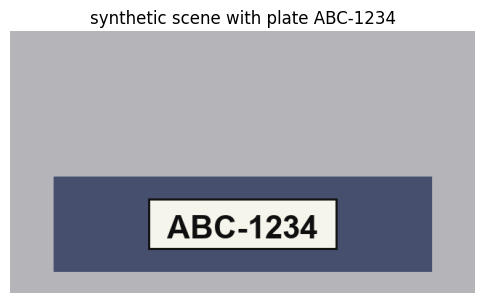

saved: ../../data/plates/synthetic_plate.png


In [2]:
def synth_plate(text="ABC-1234", out_size=(640, 360)):
    # white-ish background to look vaguely like an outdoor scene with a car
    bg = Image.new("RGB", out_size, (180, 180, 185))
    draw = ImageDraw.Draw(bg)

    # fake "car body" shape in the bottom half
    draw.rectangle([60, 200, out_size[0] - 60, out_size[1] - 30], fill=(70, 80, 110))

    # the plate itself
    pw, ph = 260, 70
    px = (out_size[0] - pw) // 2
    py = out_size[1] - 130
    draw.rectangle([px, py, px + pw, py + ph], fill=(245, 245, 235), outline=(20, 20, 20), width=3)

    # text — fall back to default font if a TTF isn't around
    try:
        font = ImageFont.truetype("/Library/Fonts/Arial Bold.ttf", 44)
    except Exception:
        try:
            font = ImageFont.truetype("DejaVuSans-Bold.ttf", 44)
        except Exception:
            font = ImageFont.load_default()
    bbox = draw.textbbox((0, 0), text, font=font)
    tw, th = bbox[2] - bbox[0], bbox[3] - bbox[1]
    tx = px + (pw - tw) // 2
    ty = py + (ph - th) // 2 - 4
    draw.text((tx, ty), text, fill=(15, 15, 15), font=font)

    return bg

img_pil = synth_plate("ABC-1234")
img_path = DATA_DIR / "synthetic_plate.png"
img_pil.save(img_path)
plt.figure(figsize=(6, 4))
plt.imshow(img_pil)
plt.axis("off")
plt.title("synthetic scene with plate ABC-1234")
plt.show()
print(f"saved: {img_path}")


## Plate detection

I try a Haar cascade for Russian plates (the one OpenCV ships with) first. If it doesn't find anything (which is common on synthetic scenes), fall back to a contour-based heuristic: threshold, find rectangular contours, keep those with plate-like aspect ratios.


Detection method: haar.  Found 1 candidate(s).


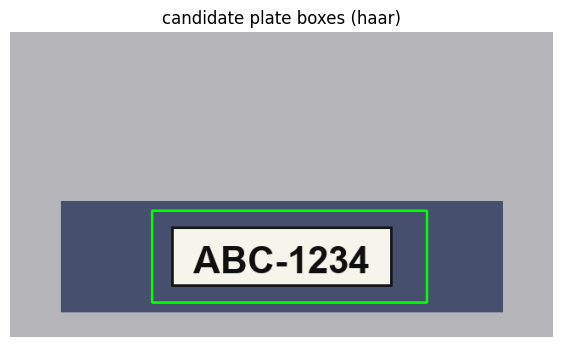

In [3]:
img = cv2.imread(str(img_path))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def haar_plate_boxes(gray_img):
    # OpenCV ships with this one; on synthetic images it often misses, that's expected
    cascade_path = cv2.data.haarcascades + "haarcascade_russian_plate_number.xml"
    if not os.path.exists(cascade_path):
        return []
    cascade = cv2.CascadeClassifier(cascade_path)
    boxes = cascade.detectMultiScale(gray_img, scaleFactor=1.1, minNeighbors=5)
    return list(boxes)

def contour_plate_boxes(gray_img):
    # threshold + contour, filter by aspect ratio + relative area
    _, bw = cv2.threshold(gray_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(bw, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    H, W = gray_img.shape
    candidates = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        ar = w / max(h, 1)
        area_frac = (w * h) / (H * W)
        # plate-ish: wide aspect, not the whole image, not microscopic
        if 2.0 < ar < 6.0 and 0.005 < area_frac < 0.25:
            candidates.append((x, y, w, h))
    # sort by area desc and return top few
    candidates.sort(key=lambda b: b[2] * b[3], reverse=True)
    return candidates[:5]

boxes = haar_plate_boxes(gray)
detection_method = "haar"
if len(boxes) == 0:
    boxes = contour_plate_boxes(gray)
    detection_method = "contour"
print(f"Detection method: {detection_method}.  Found {len(boxes)} candidate(s).")

# overlay all candidates
vis = img.copy()
for (x, y, w, h) in boxes:
    cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
plt.figure(figsize=(7, 4.5))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"candidate plate boxes ({detection_method})")
plt.show()


## Crop the best candidate and OCR it

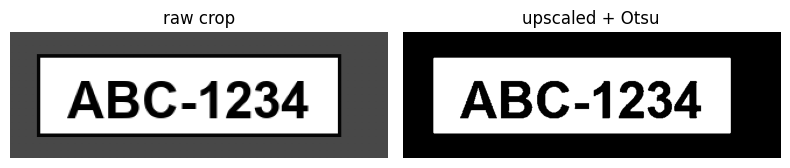

OCR output: 'ABC-1234'
Ground truth: 'ABC-1234'
Match: True


In [4]:
# pick the largest candidate as the plate
if boxes:
    x, y, w, h = max(boxes, key=lambda b: b[2] * b[3])
    crop = gray[y:y + h, x:x + w]
    # upscale + threshold helps tesseract a lot on small crops
    crop_big = cv2.resize(crop, None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC)
    _, crop_bin = cv2.threshold(crop_big, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    fig, axes = plt.subplots(1, 2, figsize=(8, 3))
    axes[0].imshow(crop, cmap="gray");      axes[0].set_title("raw crop"); axes[0].axis("off")
    axes[1].imshow(crop_bin, cmap="gray");  axes[1].set_title("upscaled + Otsu"); axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    if HAS_TESSERACT:
        try:
            # constrain charset — plates are uppercase letters / digits / dash
            config = "--psm 7 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789-"
            text = pytesseract.image_to_string(crop_bin, config=config)
            text = text.strip().replace(" ", "")
            print(f"OCR output: '{text}'")
            print(f"Ground truth: 'ABC-1234'")
            print(f"Match: {text == 'ABC-1234'}")
        except Exception as e:
            print(f"pytesseract failed: {e}\n(this typically means the Tesseract binary isn't installed)")
    else:
        print("pytesseract import failed — skipping OCR step. Plate detection still worked.")
else:
    print("no plate candidate found — would need to tune the detection heuristics")


## What I learned writing this

- The Haar cascade for Russian plates is genuinely useful on real photos but fails routinely on synthetic / cartoon-ish scenes. The fallback contour heuristic is what actually does the work in this notebook.
- pytesseract is one of those tools that's either great or terrible depending on the crop quality. Upscaling 2x + Otsu thresholding helped a lot. Without the upscale it often returned the right characters in a slightly garbled order.
- If I were building this for real, I'd skip Haar + contour entirely and use a small detection model (YOLOv8n fine-tuned on a plate dataset). The classical pipeline is here mostly because that's what the course asked for.
- See notebook 96 for the CNN-classifier version of the same problem — same student, same plate, two different approaches.
